# 06 — Inspect the application database
Run whenever you want, before or after the pipeline. These queries are read-only. If tables or data do not exist yet, the notebook reports that instead of treating an empty database as a failure.

In [19]:
%matplotlib inline

In [20]:
import sys
from pathlib import Path
project = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sqlalchemy import text


## Functions: settings
This is a copy; edit the source in 05_pipeline_walkthrough.ipynb. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [21]:
import os
from urllib.parse import quote_plus


In [22]:
def database_url():
    user = quote_plus(os.environ['DIABETES_DB_USER'])
    pwd = quote_plus(os.environ['DIABETES_DB_PASSWORD'])
    host = os.getenv('DIABETES_DB_HOST', 'diabetes-postgres.mlops-project.svc.cluster.local')
    db = quote_plus(os.getenv('DIABETES_DB_NAME', 'diabetes'))
    return f'postgresql+psycopg2://{user}:{pwd}@{host}:5432/{db}'


## Functions: pipeline
This is a copy; edit the source in 05_pipeline_walkthrough.ipynb. Run the cells in order. After saving edits in the source notebooks, run the synchronization command described in the README.

In [23]:
import io, json, os, pathlib
import pandas as pd
from sqlalchemy import create_engine, text
BUCKET='diabetes-source'
MODEL_SCHEMA_VERSION='patient_split_categorical_v2'


In [24]:
def engine(): return create_engine(database_url(),pool_pre_ping=True)


In [25]:
db = engine()
with db.connect() as connection:
    print('Connected to:', connection.execute(text('SELECT current_database()')).scalar())
    tables = pd.read_sql_query(text("SELECT table_schema, table_name FROM information_schema.tables WHERE table_schema IN ('raw','clean','audit') ORDER BY table_schema, table_name"), connection)
display(tables if not tables.empty else 'Pipeline tables have not been created yet.')

Connected to: diabetes


,table_schema,table_name
0,audit,inference_logs
1,audit,ingestion_batches
2,clean,encounters
3,raw,encounters


In [26]:
with db.connect() as connection:
    exists = {name: connection.execute(text('SELECT to_regclass(:name)'), {'name': name}).scalar() is not None
              for name in ('raw.encounters', 'clean.encounters', 'audit.ingestion_batches', 'audit.inference_logs')}
    counts = []
    for name, present in exists.items():
        if present:
            counts.append({'table': name, 'rows': connection.execute(text('SELECT count(*) FROM ' + name)).scalar()})
display(pd.DataFrame(counts) if counts else 'No pipeline tables yet.')

,table,rows
0,raw.encounters,30000
1,clean.encounters,30000
2,audit.ingestion_batches,2
3,audit.inference_logs,13973


In [27]:
if exists['audit.ingestion_batches']:
    with db.connect() as connection:
        batches = pd.read_sql_query(text('SELECT batch_id, status, row_count, started_at, completed_at FROM audit.ingestion_batches ORDER BY batch_id'), connection)
    display(batches if not batches.empty else 'No batches have been ingested yet.')

,batch_id,status,row_count,started_at,completed_at
0,batch_0001,completed,15000,2026-11-02 23:51:56.943231+00:00,2026-11-02 23:52:43.864144+00:00
1,batch_0002,completed,15000,2026-11-02 23:56:53.255122+00:00,2026-11-02 23:59:05.653806+00:00


,batch_id,split,target,encounters
0,batch_0001,test,0,2115
1,batch_0001,test,1,274
2,batch_0001,train,0,9304
3,batch_0001,train,1,1146
4,batch_0001,validation,0,1928
5,batch_0001,validation,1,233
6,batch_0002,test,0,1986
7,batch_0002,test,1,316
8,batch_0002,train,0,9251
9,batch_0002,train,1,1205


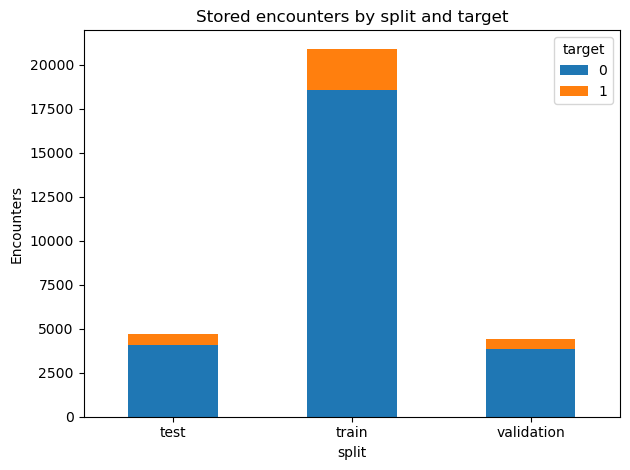

In [28]:
if exists['clean.encounters']:
    with db.connect() as connection:
        distribution = pd.read_sql_query(text('SELECT batch_id, split, target, count(*) AS encounters FROM clean.encounters GROUP BY batch_id, split, target ORDER BY batch_id, split, target'), connection)
    if distribution.empty:
        print('No cleaned encounters yet.')
    else:
        display(distribution)
        distribution.groupby(['split', 'target'])['encounters'].sum().unstack(fill_value=0).plot.bar(stacked=True, rot=0, title='Stored encounters by split and target')
        plt.ylabel('Encounters'); plt.tight_layout(); plt.show()

## Check patient separation across the processed data

In [29]:
if exists['clean.encounters']:
    with db.connect() as connection:
        overlap = connection.execute(text("SELECT count(*) FROM (SELECT patient_nbr FROM clean.encounters GROUP BY patient_nbr HAVING count(DISTINCT split) > 1) AS overlapping_patients")).scalar()
    print('Patients in more than one split:', overlap)

Patients in more than one split: 0


In [30]:
if exists['raw.encounters']:
    with db.connect() as connection:
        sample = pd.read_sql_query(text('SELECT encounter_id, patient_nbr, batch_id, ingested_at FROM raw.encounters ORDER BY encounter_id LIMIT 5'), connection)
    display(sample if not sample.empty else 'RAW is empty.')

,encounter_id,patient_nbr,batch_id,ingested_at
0,12522,48330783,batch_0001,2026-11-02 23:51:56.943231+00:00
1,15738,63555939,batch_0001,2026-11-02 23:51:56.943231+00:00
2,16680,42519267,batch_0001,2026-11-02 23:51:56.943231+00:00
3,28236,89869032,batch_0001,2026-11-02 23:51:56.943231+00:00
4,35754,82637451,batch_0001,2026-11-02 23:51:56.943231+00:00


## Inference logs and metrics
Inspect recent predictions and aggregate response times by model version. The database stores inference records; training and evaluation metrics are in MLflow.


In [31]:
if exists['audit.inference_logs']:
    with db.connect() as connection:
        logs = pd.read_sql_query(text('''
            SELECT created_at, request_id, model_name, model_version, response_ms, prediction
            FROM audit.inference_logs
            ORDER BY created_at DESC
            LIMIT 20
        '''), connection)
    display(logs if not logs.empty else 'No inference logs yet. Send a prediction to an API first.')
else:
    print('The inference log table has not been created yet.')


,created_at,request_id,model_name,model_version,response_ms,prediction
0,2026-11-03 00:22:30.221120+00:00,f390e9f4-7732-49cf-829b-20d919e1d884,diabetes-readmission,6,526.611857,"[{'prediction': 0, 'probability_readmitted_wit..."
1,2026-11-03 00:22:30.202333+00:00,8c828632-ebfb-4a92-b120-7038176a761d,diabetes-readmission,6,600.192102,"[{'prediction': 0, 'probability_readmitted_wit..."
2,2026-11-03 00:22:30.106052+00:00,1981edd7-51c6-4a37-83bd-f0c19bd30ef5,diabetes-readmission,6,627.350673,"[{'prediction': 0, 'probability_readmitted_wit..."
3,2026-11-03 00:22:30.076067+00:00,a4a9ed7a-461f-40b2-8c5d-75741eca7b3e,diabetes-readmission,6,665.460827,"[{'prediction': 0, 'probability_readmitted_wit..."
4,2026-11-03 00:22:30.060961+00:00,a009826e-8609-47e1-92fe-524c4aaa2f58,diabetes-readmission,6,547.805082,"[{'prediction': 0, 'probability_readmitted_wit..."
5,2026-11-03 00:22:29.988649+00:00,65246e0f-d6c8-4147-845e-a5f99e9eae5a,diabetes-readmission,6,505.165976,"[{'prediction': 0, 'probability_readmitted_wit..."
6,2026-11-03 00:22:29.884780+00:00,232b4f3c-ebc1-4924-af1d-de8aa835aadd,diabetes-readmission,6,305.237351,"[{'prediction': 0, 'probability_readmitted_wit..."
7,2026-11-03 00:22:29.623030+00:00,3800a275-a39c-46f8-b974-ea5a98311d58,diabetes-readmission,6,346.471883,"[{'prediction': 0, 'probability_readmitted_wit..."
8,2026-11-03 00:22:29.545877+00:00,b0af6c6f-b4d3-4827-81ac-7f05c06316b5,diabetes-readmission,6,874.888374,"[{'prediction': 0, 'probability_readmitted_wit..."
9,2026-11-03 00:22:29.503149+00:00,e0a4f84c-c11b-42ae-9055-54722f086926,diabetes-readmission,6,512.688097,"[{'prediction': 0, 'probability_readmitted_wit..."


In [32]:
if exists['audit.inference_logs']:
    with db.connect() as connection:
        metrics = pd.read_sql_query(text('''
            SELECT model_name, model_version, count(*) AS inference_requests,
                   round(avg(response_ms)::numeric, 2) AS avg_response_ms,
                   round(max(response_ms)::numeric, 2) AS max_response_ms
            FROM audit.inference_logs
            GROUP BY model_name, model_version
            ORDER BY model_name, model_version
        '''), connection)
    display(metrics if not metrics.empty else 'No inference metrics yet.')


,model_name,model_version,inference_requests,avg_response_ms,max_response_ms
0,diabetes-readmission,6,14063,558.68,5440.81


Run this notebook again after notebook 05 or an Airflow DAG run to see updated counts. An empty table means the connection works but no data has been processed into that table yet.